# B06 怎样根据历史天气预测明天的最高温度？

使用本地真实 Jena 日统计数据。在今天观测结束后预测明天最高温，核心比较持续性基线与 Ridge 线性模型；用时间划分防止看到未来。

先修：B01—B05；学习 shift、训练/验证/测试、Pipeline、拟合与预测。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 对齐到每日时间轴
日期缺口会让 shift(1) 变成上一条而非昨天，因此先补齐每日索引。保留缺失，让后续明确删除不完整窗口。输入来自 assets/data/jena_daily.csv，单位与来源见数据说明。

In [2]:
import pandas as pd, numpy as np, json
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
daily = pd.read_csv(COURSE_ROOT / 'assets/data/jena_daily.csv', parse_dates=['date']).sort_values('date')
assert daily['date'].is_unique
daily = daily.set_index('date').asfreq('D')
assert len(daily) > 365
print(daily.head(), daily.isna().sum())


            temp_max  temp_min  temp_mean    pressure   humidity
date                                                            
2009-01-01     -4.17     -9.91  -6.810629  999.145594  91.086014
2009-01-02     -2.12     -4.97  -3.728194  999.600625  92.086806
2009-01-03     -0.82    -10.00  -5.271736  998.548611  76.458056
2009-01-04     -0.63     -2.54  -1.375208  988.510694  89.417361
2009-01-05     -1.44    -12.54  -4.867153  990.405694  86.260417 temp_max     5
temp_min     5
temp_mean    5
pressure     5
humidity     5
dtype: int64


## 2. 把预测问题变成表格
一行的索引是今天。当前温度与过去 1—7 天可用，target 是明天。`shift(-1)` 只用于构造标签，绝不能放入特征。按时间前 60%/中 20%/后 20% 划分。

In [3]:
def make_weather_table(frame, window=7, target='temp_max'):
    table = frame[['temp_max', 'temp_min', 'temp_mean', 'pressure', 'humidity']].copy()
    for lag in range(1, window + 1):
        table[f'temp_lag_{lag}'] = frame['temp_max'].shift(lag)
    table['target'] = frame[target].shift(-1)
    table['forecast_date'] = frame.index + pd.Timedelta(days=1)
    return table.dropna()
table = make_weather_table(daily)
features = [c for c in table.columns if c not in ['target', 'forecast_date']]
a, b = int(len(table)*0.6), int(len(table)*0.8)
train, validation, test = table.iloc[:a], table.iloc[a:b], table.iloc[b:]
assert train['forecast_date'].max() < validation['forecast_date'].min()
assert validation['forecast_date'].max() < test['forecast_date'].min()


## 3. 只用验证集选择正则化强度
标准化必须在训练集内拟合，所以与 Ridge 放入 Pipeline。验证选择完成后，用训练加验证重新拟合一次；测试段只用于最后报告。比较不同模型时不得更换测试日期。

In [4]:
validation_scores = {}
for alpha in [0.1, 1.0, 10.0, 100.0]:
    candidate = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    candidate.fit(train[features], train['target'])
    validation_scores[alpha] = float(mean_absolute_error(validation['target'], candidate.predict(validation[features])))
best_alpha = min(validation_scores, key=validation_scores.get)
model = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha))
development = table.iloc[:b]
model.fit(development[features], development['target'])
prediction = model.predict(test[features])
baseline = test['temp_max'].to_numpy()


## 4. 评价与失败日期
MAE 是平均绝对误差，单位 °C。先报告整体再检查误差最大的日期；不能删除难预测日来美化分数。图上不完整窗口保留为空缺，不能用连线暗示已补齐观测。若线性模型未胜出，也如实保留结论。

In [5]:
results = pd.DataFrame({'date': test['forecast_date'].to_numpy(), 'actual': test['target'].to_numpy(), 'persistence': baseline, 'ridge': prediction})
results['absolute_error'] = abs(results['actual'] - results['ridge'])
metrics = {'rows': len(table), 'train': len(train), 'validation': len(validation), 'test': len(test), 'best_alpha': best_alpha, 'validation_mae': validation_scores, 'persistence_mae': float(mean_absolute_error(test['target'], baseline)), 'ridge_mae': float(mean_absolute_error(test['target'], prediction))}
results.to_csv(OUT_DIR / 'predictions.csv', index=False)
results.nlargest(10, 'absolute_error').to_csv(OUT_DIR / 'largest_errors.csv', index=False)
(OUT_DIR / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
results.set_index('date')[['actual', 'persistence', 'ridge']].tail(90).asfreq('D').plot()
plt.ylabel('最高温度 / °C'); plt.tight_layout(); plt.savefig(OUT_DIR / 'forecast.png'); plt.close(); print(metrics)


{'rows': 2893, 'train': 1735, 'validation': 579, 'test': 579, 'best_alpha': 10.0, 'validation_mae': {0.1: 2.3907229325734365, 1.0: 2.388545293821509, 10.0: 2.3844934701153493, 100.0: 2.435917364319479}, 'persistence_mae': 2.5210708117443867, 'ridge_mae': 2.4652161666724424}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

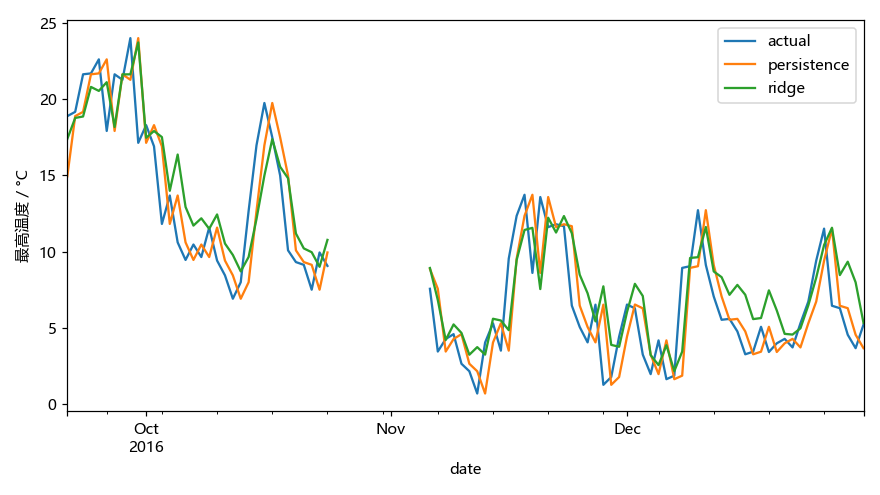

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
这是单站历史统计预测，不是专业数值天气预报。相邻日特征可以重叠，但每次预测只能使用当时已观测的信息；未使用未来天气特征。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。